Question 1. Exact Line Search for a Quadratic Objective J(w) = ½ wᵀAw + bᵀw.

(a) Implement the function below. [2 marks] 
    exact_line_search_quadratic(A, b, w0, num_steps) 
    Inputs: 
        • A: an n × n symmetric positive-definite matrix 
        • b: a NumPy array of length n. 
        • w0: a NumPy array of length n containing the initial point. 
        • num_steps: a non-negative integer giving the maximum number of iterations. 
    At iteration t, calculate the negative gradient direction and exact step size: 
        gₜ = −(Awₜ + b)
        αₜ = (gₜᵀgₜ)/(gₜᵀAgₜ)
        wₜ₊₁ = wₜ + αₜgₜ    
    Stop if ||Awₜ + b||₂ < 10⁻¹⁰ or after num_steps iterations, whichever occurs first. Avoid dividing by zero if the gradient is numerically zero. (grad + E)
    Return: a Python list named iterates containing copies of the initial point and every point generated. Thus iterates[0] is w₀, iterates[t] is wₜ, and the list has at most num_steps + 1 entries.

In [2]:
import numpy as np

print("Enter n: ")   
n = int(input("n: "))
'''
DIMENSIONS
w- n x 1,   A- n x n,   b- n x 1,   grad- n x 1,   alpha- 1 x 1
'''
A = np.round(np.random.uniform(-10, 10, [n, n]), 8)  
b = np.round(np.random.uniform(-10, 10, [n, 1]), 8)
w0 = np.round(np.random.uniform(-10, 10, [n, 1]), 8)

def exact_line_search_quadratic(A, b, w0, num_steps):
    E = 1e-9   # tolerance
    grad, alpha = [], []
    iterates = [w0]

    for t in range(num_steps):
        grad_t = - (A @ iterates[t] + b)  # over np array  (n x 1)
        L2 = np.linalg.norm(grad_t)
        if L2 < E:   # if L2 = 0, returns as well
            return iterates, grad, alpha
        grad.append(grad_t)
        alpha_t = (np.transpose(grad[t]) @ grad[t]) / (np.transpose(grad[t]) @ (A @ grad[t]))  # 2nd derivative for alpha val [minimizes J]
        alpha.append(alpha_t)
        # weight update
        w_new = iterates[t] + alpha[t] * grad[t]   # scalar alpha
        iterates.append(w_new)

    return iterates, grad, alpha

Enter n: 


(b) Use the following data.  
    A = [ 2 0         ,  b = [0, 0]ᵀ    ,  w₀ = [2.0, 1.0]ᵀ
          0 8 ] 
    Therefore, J(w₁, w₂) = w₁² + 4w₂². 
    1. Run the function with num_steps = 10. Print w₀ and every iterate returned by the function. [0.5M] 
    2. Print J(wₜ) for every returned iterate wₜ. [0.5M] 
    3. For t = 0, 1, 2, 3, 4, calculate and print gₜᵀgₜ₊₁. Define each gₜ using gₜ = −(Awₜ + b), and state whether the dot products are approximately zero within floating-point precision. [0.5M] 

In [3]:
'''
2 Variable Quadratic LS

Newton's Method-----> subtract ratio of grad to curvature (hessian) from approximation for new val.
'''

A = np.array([[2, 0],   # Hessian
              [0, 8]])

b = np.array([[0], 
              [0]])

w0 = np.array([[2.0], 
              [1.0]])   #  init- w0 = [w1, w2] T

def J_optim(w):
    J = np.float_power(w[0, 0], 2) + 4 * np.float_power(w[1, 0], 2)
    return J 

steps = 10
iterates, grads, ALPHAS = exact_line_search_quadratic(A, b, w0, steps)

for i in range(steps):
    print("\nAt ", iterates[i])
    print("J value: ",J_optim(iterates[i]))    

for t in range(5):
    print("\nGRADIENT CHECKS at t = ", t)
    dotty = np.transpose(grads[t]) @ grads[t + 1]
    print(dotty)

'''
The dot product is 0 due to limitations in representation for floating point arithmetic, there is always a huge margin of error when calculating dot product. 
Extremely small values near zero in representation due to calculation constraints, this does not mean the actual value is always zero. 
The dot product is zero only when the vectors are perpendicular to each other (excluding the case of zero vectors).
'''
    


At  [[2.]
 [1.]]
J value:  8.0

At  [[ 1.41176471]
 [-0.17647059]]
J value:  2.117647058823529

At  [[0.52941176]
 [0.26470588]]
J value:  0.5605536332179932

At  [[ 0.37370242]
 [-0.0467128 ]]
J value:  0.14838184408711588

At  [[0.14013841]
 [0.0700692 ]]
J value:  0.0392775469642365

At  [[ 0.09892123]
 [-0.01236515]]
J value:  0.010396997725827297

At  [[0.03709546]
 [0.01854773]]
J value:  0.002752146456836635

At  [[ 0.02618503]
 [-0.00327313]]
J value:  0.0007285093562214622

At  [[0.00981939]
 [0.00490969]]
J value:  0.00019284071194097528

At  [[ 0.00693133]
 [-0.00086642]]
J value:  5.1046070807905226e-05

GRADIENT CHECKS at t =  0
[[-3.55271368e-15]]

GRADIENT CHECKS at t =  1
[[0.]]

GRADIENT CHECKS at t =  2
[[1.44328993e-15]]

GRADIENT CHECKS at t =  3
[[1.11022302e-16]]

GRADIENT CHECKS at t =  4
[[-1.38777878e-17]]


'\nThe dot product is 0 due to limitations in representation for floating point arithmetic, there is always a huge margin of error when calculating dot product. \nExtremely small values near zero in representation due to calculation constraints, this does not mean the actual value is always zero. \nThe dot product is zero only when the vectors are perpendicular to each other (excluding the case of zero vectors).\n'

(c) Plot the optimization path. [1M] 
    Generate a two-dimensional contour plot of J(w₁, w₂) = w₁² + 4w₂². Overlay the path w₀ → w₁ → ⋯ → w₁₀ (or all iterates returned if the stopping criterion is met early). 
    • Mark and label the initial point, the iterates, and the minimizer (0, 0). 
    • Draw line segments joining consecutive iterates.
    • At every intermediate iterate for which both adjacent path segments exist, visually mark the angle between the incoming segment wₜ − wₜ₋₁ and outgoing segment wₜ₊₁ − wₜ. Indicate the expected approximately 90° turn; do not describe this as a contour point of tangency. 
    • Include axis labels, a title, a legend, and a grid. 

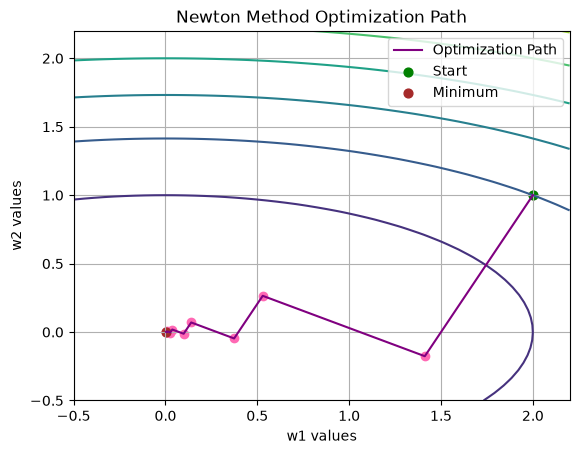

In [5]:
import matplotlib.pyplot as plt

w1 = np.linspace(-.5, 2.2, 50)
w2 = np.linspace(-.5, 2.2, 50)

W1, W2 = np.meshgrid(w1, w2)
J = np.square(W1) + 4*np.square(W2)
plt.contour(W1, W2, J)

iterates_array = np.array(iterates)
plt.plot(iterates_array[:, 0], iterates_array[:, 1], color= 'purple', label= 'Optimization Path')
plt.scatter(iterates_array[:, 0], iterates_array[:, 1], color= 'hotpink')
plt.scatter(iterates_array[0, 0], iterates_array[0, 1], c= 'green', label='Start', s= 40)
plt.scatter(iterates_array[-1, 0], iterates_array[-1, 1], c= 'brown', label= 'Minimum', s= 40)

plt.xlabel("w1 values")
plt.ylabel("w2 values")
plt.legend()
plt.grid(True)
plt.title('Newton Method Optimization Path')
plt.show()

Question 2. Gradient Descent, Momentum and RMSProp. Consider the loss function J(w₁, w₂) = w₁² + 10w₂². 

(a) Implement the following three optimizers from scratch using NumPy. Each function must return the list of iterates, including the initial point w₀ and the point after each update. [3 marks] 
    • vanilla_gd(grad_fn, w0, α, num_iters) 
    • momentum_gd(grad_fn, w0, α, β, num_iters) 
    • rmsprop_gd(grad_fn, w0, α, ρ, ε, num_iters) 
    Use grad_fn(w) to obtain the gradient at w. 
    For vanilla gradient descent, update w using w ← w − α grad_fn(w). 
    For momentum, use velocity v₀ = 0 and vₜ₊₁ = βvₜ + grad_fn(wₜ), followed by wₜ₊₁ = wₜ − αvₜ₊₁. 
    For RMSProp, initialize the running squared-gradient average s₀ = 0, update sₜ₊₁ = ρsₜ + (1 − ρ)(grad_fn(wₜ) ⊙ grad_fn(wₜ)), and update wₜ₊₁ = wₜ − α grad_fn(wₜ)/(√sₜ₊₁ + ε), with operations performed element-wise. Here, ⊙ and division are element-wise operations; ε is a small positive constant to avoid division by 0. 

In [6]:
H = np.array([[2, 0],   
              [0, 20]])

def grad_fn(w):
    delta_J = np.array([[2 * w[0, 0]],
                        [20 * w[1, 0]]])
    return delta_J


def J_func_optim(w):
    return w[0, 0]**2 + 10 * w[1, 0] **2   # never -ve


def vanilla_gd(w0, alpha, num_iters):
    iterates = [w0]
    for k in range(num_iters):
        w_new = iterates[k] - alpha * grad_fn(iterates[k])
        iterates.append(w_new)    
        
    return iterates


def momentum_gd(w0, alpha, beta, num_iters):
    iterates = [w0]
    v = [0]

    for t in range(num_iters):
        v_new = beta * v[t] + grad_fn(iterates[t])
        v.append(v_new)
        w_new = iterates[t] - alpha * v[t + 1]
        iterates.append(w_new)

    return iterates


def rmsprop_gd(w0, alpha, rho, tolerance, num_iters):
    iterates = [w0]
    s = [0]

    for i in range(num_iters):
        s_next = rho * s[i] + (1 - rho) * (grad_fn(iterates[i] * grad_fn(iterates[i])))
        s.append(s_next)
        w_next = iterates[i] - (alpha * grad_fn(iterates[i])) / np.sqrt(s[i + 1] + tolerance)
        iterates.append(w_next)
    
    return iterates

(b) Run and plot the optimizers.  
    1.  Initialize all 3 methods at w₀ = [3.0, 1.0]ᵀ and run 50 iterations with learning rate α = 0.05. Use the same initial point and iteration count for all methods. Choose and state the values of β, ρ and ε used for Momentum and RMSProp. [1M] 
    2.  Plot J(wₜ) against iteration t for all 3 methods on a single plot with a logarithmic vertical axis. If a loss reaches zero numerically, handle the log-scale display without taking log(0). [1.5M] 
    3.  Plot the 3 optimization paths side-by-side over contour lines of J(w₁, w₂). Use the same contour levels and axis limits in all 3 panels. [1M] 

In [7]:
w0 = np.array([[3.0],
               [1.0]])

vanilla_iterates = vanilla_gd(w0, alpha= .05, num_iters= 50)
momentum_iterates = momentum_gd(w0, alpha= .05, beta= .6, num_iters= 50)
rmsprop_iterates = rmsprop_gd(w0, alpha= .05, rho= .2, tolerance= 1e-8, num_iters= 50)

'''
beta = .6, rho = .2, tolerance = 1e-8
'''

'\nbeta = .6, rho = .2, tolerance = 1e-8\n'

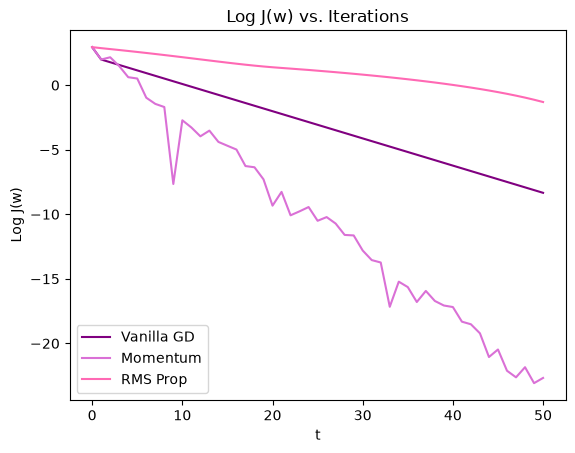

In [8]:
plt.title("Log J(w) vs. Iterations")
plt.xlabel("t")
plt.ylabel("Log J(w)")
t = np.arange(0, 51, 1).reshape(51, 1)

vanilla_func, momentum_func, rms_func = [], [], []

for i in range(51):
    v = J_func_optim(vanilla_iterates[i])
    if v == 0:
        v = 1e-9   # handles log(0)
    vanilla_func.append(np.log(v))
    
    m = J_func_optim(momentum_iterates[i])
    if m == 0:
        m = 1e-9
    momentum_func.append(np.log(m))
    
    r = J_func_optim(rmsprop_iterates[i])
    if r == 0:
        r = 1e-9
    rms_func.append(np.log(r))


plt.plot(t, vanilla_func, color= 'purple', label= 'Vanilla GD')
plt.plot(t, momentum_func, color= 'orchid', label= 'Momentum')
plt.plot(t, rms_func, color= 'hotpink', label= 'RMS Prop')
plt.legend()
plt.show()

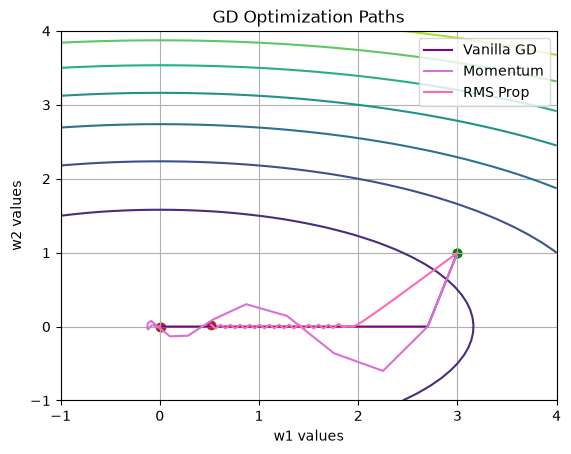

In [10]:
optims = { 'type': [vanilla_iterates, momentum_iterates, rmsprop_iterates],
            'color': ['purple', 'orchid', 'hotpink']
            }

type = ['Vanilla GD', 'Momentum', 'RMS Prop']

w1_other = np.linspace(-1, 4, 50)
w2_other = np.linspace(-1, 4, 50)

W1_other, W2_other = np.meshgrid(w1_other, w2_other)
J_other = np.square(W1_other) + 4*np.square(W2_other)
plt.contour(W1_other, W2_other, J_other)

for optimizer in range(3):
    plt.plot(np.array(optims['type'][optimizer])[:, 0], np.array(optims['type'][optimizer])[:, 1], color= optims['color'][optimizer], label= type[optimizer])
    plt.scatter(np.array(optims['type'][optimizer])[0, 0], np.array(optims['type'][optimizer])[0, 1], c= 'green')
    plt.scatter(np.array(optims['type'][optimizer])[-1, 0], np.array(optims['type'][optimizer])[-1, 1], c= 'brown')

plt.legend()
plt.grid(True)
plt.xlabel('w1 values')
plt.ylabel('w2 values')
plt.title('GD Optimization Paths')
plt.show()